# Detecção de Ataques em Redes IoT com Aprendizado de Máquina
**MBA em Ciência de Dados — Unifor · Aprendizado de Máquina Supervisionado · Prof. Caio Ponte · Turma 12**

Base: **RT-IoT2022**, com tráfego real capturado em uma rede IoT (UCI Machine Learning Repository).

Roteiro do notebook (segue a estrutura exigida no enunciado):
1. Definição do Problema
2. Análise Exploratória dos Dados (EDA)
3. Pré-processamento dos Dados
4. Treinamento do Modelo (Gradient Boosting)
5. Avaliação do Modelo e Conclusão

In [1]:
import warnings, os, time
from typing import Any, cast
warnings.filterwarnings("ignore")

# False = carrega o modelo e a importância das variáveis já calculados (notebook roda em ~1 min)
# True  = refaz a busca de hiperparâmetros (~10-13 min) e a importância (~4 min) e salva de novo
RETREINAR = False
ARQ_MODELO = "modelos/busca_gb.joblib"

import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import loguniform, randint
import sklearn, imblearn

# Versões usadas: o modelo salvo só é reaproveitado se tiver sido gerado com as mesmas
VERSOES = {"scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__}

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold"})
CORES = {"Normal": "#4C72B0", "Ataque": "#C44E52"}

def mostrar():
    plt.tight_layout()
    plt.show()

## 1. Definição do Problema

**Contexto.** Lâmpadas, sensores e assistentes de voz estão em casas, indústrias e hospitais. Esses aparelhos costumam ter pouca memória, firmware simples e senhas fracas, e por isso são alvos fáceis. Um sistema de detecção de intrusão (IDS) observa o tráfego da rede e precisa dizer, para cada conexão, se ela é legítima ou um ataque, e de qual tipo.

**Problema.** Classificar cada fluxo de rede em um de 12 tipos de tráfego: 3 normais (aparelhos IoT legítimos) e 9 ataques.
- Tipo: classificação multiclasse supervisionada.
- Cada linha: um fluxo de rede, isto é, uma conexão resumida em estatísticas de pacotes, bytes, tempos e flags TCP.
- Target: `Attack_type`.

| Grupo | Classe | O que é |
|---|---|---|
| Normal | `Thing_Speak` | LED que envia dados para a plataforma ThingSpeak |
| Normal | `MQTT_Publish` | Sensor de temperatura publicando via protocolo MQTT |
| Normal | `Wipro_bulb` | Lâmpada inteligente Wipro |
| Ataque | `DOS_SYN_Hping` | Negação de serviço por inundação de pacotes SYN (ferramenta Hping) |
| Ataque | `DDOS_Slowloris` | Negação de serviço distribuída que mantém conexões HTTP abertas |
| Ataque | `ARP_poisioning` | Envenenamento de ARP (homem no meio) |
| Ataque | `Metasploit_Brute_Force_SSH` | Força bruta de senha SSH (Metasploit) |
| Ataque | `NMAP_UDP_SCAN`, `NMAP_TCP_scan`, `NMAP_XMAS_TREE_SCAN`, `NMAP_FIN_SCAN`, `NMAP_OS_DETECTION` | Varreduras de reconhecimento da rede (Nmap) |

**Motivação.** Saber o tipo de ataque permite reagir do jeito certo: bloquear o IP que tenta adivinhar senhas, limitar pacotes SYN durante um DoS, isolar um aparelho comprometido. Como os aparelhos IoT têm poucos recursos, o modelo também precisa ser leve e não pode deixar passar os ataques raros.

**Origem dos dados.** RT-IoT2022, do UCI Machine Learning Repository (id 942, DOI 10.24432/C5P338, licença CC BY 4.0): https://archive.ics.uci.edu/dataset/942/rt-iot2022. A base foi criada por B. S. Sharmila e Rohini Nagapadma (National Institute of Engineering, Mysuru, Índia) e publicada na revista *Cybersecurity* em 2023. O tráfego foi capturado de verdade numa rede IoT de laboratório, com o monitor Zeek e o plugin Flowmeter: o tráfego normal vem de aparelhos reais, e os ataques foram feitos na rede com ferramentas reais (Hping, Nmap, Metasploit). São 123.117 fluxos e 85 colunas.

In [2]:
CAMINHO = "data/rt_iot2022/RT_IOT2022.csv"
if not os.path.exists(CAMINHO):
    from ucimlrepo import fetch_ucirepo  
    os.makedirs(os.path.dirname(CAMINHO), exist_ok=True)
    dados = fetch_ucirepo(id=942).data
    if dados is None:
        raise RuntimeError("Não foi possível baixar a RT-IoT2022 da UCI")
    dados.original.to_csv(CAMINHO, index=False)

df = pd.read_csv(CAMINHO)
print(df.shape)
df.head()

(123117, 85)


,id,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,29729182.96,29729182.96,29729182.96,29729182.96,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,...,0.0,29855277.06,29855277.06,29855277.06,29855277.06,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,29842149.02,29842149.02,29842149.02,29842149.02,0.0,64240,26847,502,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,0.0,29913774.97,29913774.97,29913774.97,29913774.97,0.0,64240,26847,502,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,0.0,29814704.90,29814704.90,29814704.90,29814704.90,0.0,64240,26847,502,MQTT_Publish


### Dicionário de dados (por grupo de colunas)

As 83 features descrevem cada fluxo. Como são muitas, o dicionário está agrupado. `fwd` = sentido origem → destino, `bwd` = sentido destino → origem.

| Grupo | Colunas (exemplos) | Descrição | Uso no modelo |
|---|---|---|---|
| Identificação | `id` | Número sequencial da linha **dentro de cada classe** | ❌ removida (vazamento, ver EDA) |
| Portas | `id.orig_p`, `id.resp_p` | Porta de origem e de destino | ❌ removidas (artefato do laboratório, ver EDA) |
| Protocolo | `proto`, `service` | Protocolo de transporte (tcp/udp/icmp) e serviço de aplicação (dns, mqtt, http…) | ✅ features categóricas |
| Duração e volume | `flow_duration`, `fwd_pkts_tot`, `bwd_pkts_tot`, `fwd_data_pkts_tot` | Duração do fluxo e quantidade de pacotes em cada sentido | ✅ features |
| Taxas | `fwd_pkts_per_sec`, `flow_pkts_per_sec`, `down_up_ratio`, `payload_bytes_per_second` | Velocidade de envio de pacotes e bytes | ✅ features |
| Cabeçalhos | `fwd_header_size_tot/min/max`, `bwd_header_size_*` | Tamanho dos cabeçalhos dos pacotes | ✅ features |
| Flags TCP | `flow_SYN_flag_count`, `flow_ACK_flag_count`, `flow_FIN_flag_count`, `flow_RST_flag_count`… | Quantas vezes cada flag TCP apareceu | ✅ features (`bwd_URG_flag_count` é constante e é removida) |
| Payload | `fwd_pkts_payload.min/max/tot/avg/std`, `bwd_*`, `flow_*` | Estatísticas do conteúdo útil dos pacotes | ✅ features |
| Tempo entre pacotes | `fwd_iat.*`, `bwd_iat.*`, `flow_iat.*` | *Inter-arrival time*: intervalo entre pacotes consecutivos | ✅ features |
| Subfluxos e rajadas | `fwd_subflow_*`, `fwd_bulk_*`, `bwd_bulk_*` | Comportamento em sub-sequências e rajadas de pacotes | ✅ features |
| Atividade | `active.*`, `idle.*` | Tempo em que o fluxo ficou ativo ou ocioso | ✅ features |
| Janela TCP | `fwd_init_window_size`, `bwd_init_window_size`, `fwd_last_window_size` | Tamanho da janela de recepção TCP | ✅ features |
| **Target** | `Attack_type` | **Tipo de tráfego (12 classes)** | 🎯 **target** |

In [3]:
NORMAIS = ["Thing_Speak", "MQTT_Publish", "Wipro_bulb"]
NOMES = {"DOS_SYN_Hping": "DoS SYN", "Thing_Speak": "ThingSpeak (normal)", "ARP_poisioning": "ARP poisoning",
         "MQTT_Publish": "MQTT (normal)", "NMAP_UDP_SCAN": "Nmap UDP", "NMAP_XMAS_TREE_SCAN": "Nmap XMAS",
         "NMAP_OS_DETECTION": "Nmap OS", "NMAP_TCP_scan": "Nmap TCP", "DDOS_Slowloris": "DDoS Slowloris",
         "Wipro_bulb": "Wipro bulb (normal)", "Metasploit_Brute_Force_SSH": "Brute force SSH", "NMAP_FIN_SCAN": "Nmap FIN"}
df["Grupo"] = np.where(df["Attack_type"].isin(NORMAIS), "Normal", "Ataque")
df.info(verbose=False)

<class 'pandas.DataFrame'>
RangeIndex: 123117 entries, 0 to 123116
Columns: 86 entries, id to Grupo
dtypes: float64(47), int64(35), str(4)
memory usage: 80.8 MB


## 2. Análise Exploratória dos Dados (EDA)
Itens cobertos: qualidade e estatísticas descritivas, balanceamento de classes, distribuições, protocolo e serviço por classe, outliers, matriz de correlação e redução de dimensionalidade (PCA e t-SNE). A base não tem coordenadas geográficas nem carimbo de tempo, então mapas e análise temporal não se aplicam.

### 2.1 Qualidade e estatísticas descritivas

In [4]:
print("Valores faltantes:", df.isna().sum().sum())
print("Linhas duplicadas (ignorando id):", df.drop(columns="id").duplicated().sum())
num_all = df.select_dtypes("number").drop(columns=["id"])
print("Colunas constantes:", [c for c in num_all if num_all[c].nunique() <= 1])
CHAVE = ["flow_duration", "fwd_pkts_tot", "bwd_pkts_tot", "flow_pkts_per_sec", "fwd_pkts_payload.avg",
         "flow_iat.avg", "payload_bytes_per_second", "fwd_init_window_size"]
df[CHAVE].describe().T.round(2)

Valores faltantes: 0


Linhas duplicadas (ignorando id): 5195
Colunas constantes: ['bwd_URG_flag_count']


,count,mean,std,min,25%,50%,75%,max
flow_duration,123117.0,3.81,130.01,0.0,0.00,0.00,0.00,2.172834e+04
fwd_pkts_tot,123117.0,2.27,22.34,0.0,1.00,1.00,1.00,4.345000e+03
bwd_pkts_tot,123117.0,1.91,33.02,0.0,1.00,1.00,1.00,1.011200e+04
flow_pkts_per_sec,123117.0,703568.29,741563.42,0.0,149.09,493447.53,1048576.00,2.097152e+06
fwd_pkts_payload.avg,123117.0,100.52,46.10,0.0,120.00,120.00,120.00,1.319370e+03
flow_iat.avg,123117.0,139654.49,874802.64,0.0,0.95,4.05,5.01,7.283576e+07
payload_bytes_per_second,123117.0,41053451.79,44857059.63,0.0,2580.98,29606851.76,55924053.33,1.258291e+08
fwd_init_window_size,123117.0,6118.91,18716.31,0.0,64.00,64.00,64.00,6.553500e+04


In [5]:
assimetria = num_all.skew().abs().sort_values(ascending=False)
print(f"Assimetria (skew) mediana das features numéricas: {assimetria.median():.1f}")
print(f"Features com |skew| > 5: {(assimetria > 5).sum()} de {len(assimetria)}")
df.describe(include=["object"]).T

Assimetria (skew) mediana das features numéricas: 27.4
Features com |skew| > 5: 62 de 81


,count,unique,top,freq
proto,123117,3,tcp,110427
service,123117,10,-,102861
Attack_type,123117,12,DOS_SYN_Hping,94659
Grupo,123117,2,Ataque,110610


Não há valores faltantes, mas há 5.195 linhas duplicadas e uma coluna constante. As variáveis numéricas são muito assimétricas (skew mediano de 27): quase todos os fluxos são curtos e pequenos, e uns poucos são enormes. Por isso a média fica muito acima da mediana, e vale aplicar logaritmo no pré-processamento.

### 2.2 Balanceamento de classes

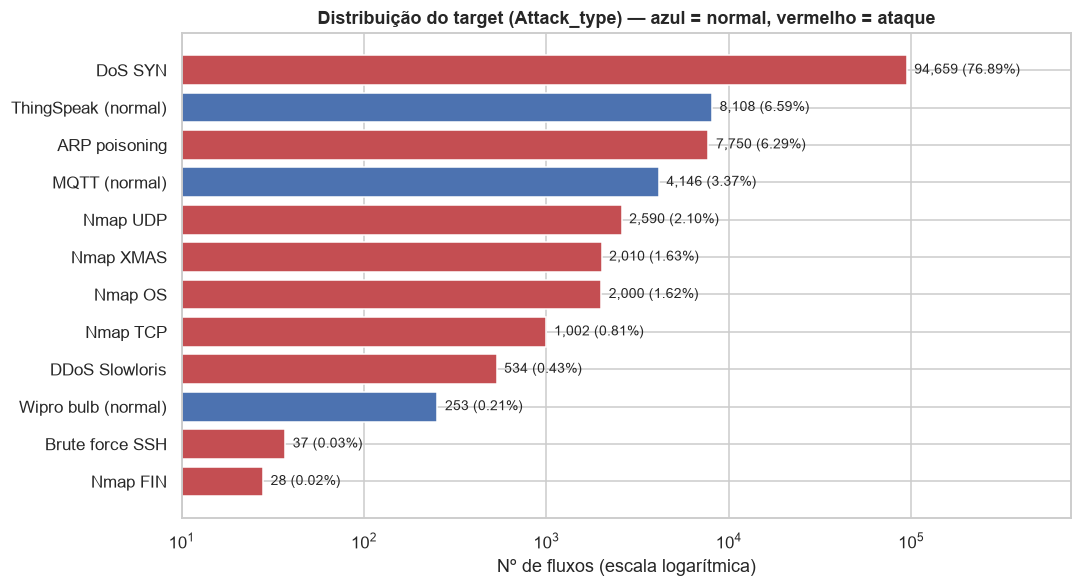

Grupo
Ataque    0.8984
Normal    0.1016
Name: proportion, dtype: float64


In [6]:
cont = df["Attack_type"].value_counts()
fig, ax = plt.subplots(figsize=(10, 5.5))
cores = [CORES["Normal"] if c in NORMAIS else CORES["Ataque"] for c in cont.index]
ax.barh([NOMES[c] for c in cont.index], cont.to_numpy(), color=cores)
ax.set_xscale("log")
for i, v in enumerate(cont.to_numpy()):
    ax.text(v * 1.1, i, f"{v:,} ({v/len(df):.2%})", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Nº de fluxos (escala logarítmica)")
ax.set_title("Distribuição do target (Attack_type) — azul = normal, vermelho = ataque")
ax.set_xlim(10, cont.max() * 8)
mostrar()
print(df["Grupo"].value_counts(normalize=True).round(4))

O desbalanceamento é extremo. O DoS SYN sozinho tem 77% das linhas, enquanto o brute force SSH tem 37 e a varredura FIN tem 28. Um modelo que sempre responde "DoS" já acerta 77%, então a acurácia não serve como métrica principal. Vamos usar o F1 macro, que dá o mesmo peso a todas as classes, e olhar também as métricas de cada classe. No pré-processamento, testamos reduzir o DoS (undersampling) e criar exemplos das classes raras (SMOTE).

### 2.3 Vazamento de dados: a coluna `id` e as portas

In [7]:
resumo_id = df.groupby("Attack_type").agg(linhas=("id", "size"), id_min=("id", "min"), id_max=("id", "max"))
display(resumo_id.sort_values("linhas", ascending=False))

portas = pd.Series(df.groupby("Attack_type")["id.resp_p"].agg(lambda s: s.value_counts(normalize=True).iloc[0]))
print("Fração de fluxos na porta de destino mais comum, por classe:")
print(portas.sort_values(ascending=False).round(3).to_string())

Xa, Xb, ya, yb = train_test_split(df[["id", "id.resp_p"]], df["Attack_type"], test_size=0.2,
                                  stratify=df["Attack_type"], random_state=RANDOM_STATE)
for cols in (["id"], ["id.resp_p"]):
    arv = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xa[cols], ya)
    print(f"Árvore usando só {cols}: acurácia {accuracy_score(yb, arv.predict(Xb[cols])):.3f}")

,linhas,id_min,id_max
Attack_type,,,
DOS_SYN_Hping,94659,0,94658
Thing_Speak,8108,0,8107
ARP_poisioning,7750,0,7749
MQTT_Publish,4146,0,4145
NMAP_UDP_SCAN,2590,0,2589
NMAP_XMAS_TREE_SCAN,2010,0,2009
NMAP_OS_DETECTION,2000,0,1999
NMAP_TCP_scan,1002,0,1001
DDOS_Slowloris,534,0,533


Fração de fluxos na porta de destino mais comum, por classe:
Attack_type
DOS_SYN_Hping                 1.000
MQTT_Publish                  0.999
DDOS_Slowloris                0.991
NMAP_FIN_SCAN                 0.857
Metasploit_Brute_Force_SSH    0.757
Thing_Speak                   0.489
Wipro_bulb                    0.423
ARP_poisioning                0.409
NMAP_UDP_SCAN                 0.056
NMAP_TCP_scan                 0.003
NMAP_XMAS_TREE_SCAN           0.002
NMAP_OS_DETECTION             0.001


Árvore usando só ['id']: acurácia 0.703


Árvore usando só ['id.resp_p']: acurácia 0.915


Duas coisas na base entregam a resposta:
- O `id` não identifica a linha na base inteira: ele recomeça do zero em cada classe. Um `id` acima de 8.107 (o maior do ThingSpeak, a segunda maior classe) só pode ser DoS. Só com essa coluna, uma árvore acerta 70%. É vazamento, e a coluna sai.
- As portas: 100% do DoS SYN vai para a porta 21, e o MQTT usa quase sempre a 1883. Só com a porta de destino, a árvore acerta 91%. Isso é coisa do laboratório (o pesquisador escolheu atacar a porta 21); um atacante de verdade usa qualquer porta. As duas colunas de porta também saem, para o modelo ter que aprender pelo comportamento do tráfego.

### 2.4 Distribuições das principais variáveis por classe

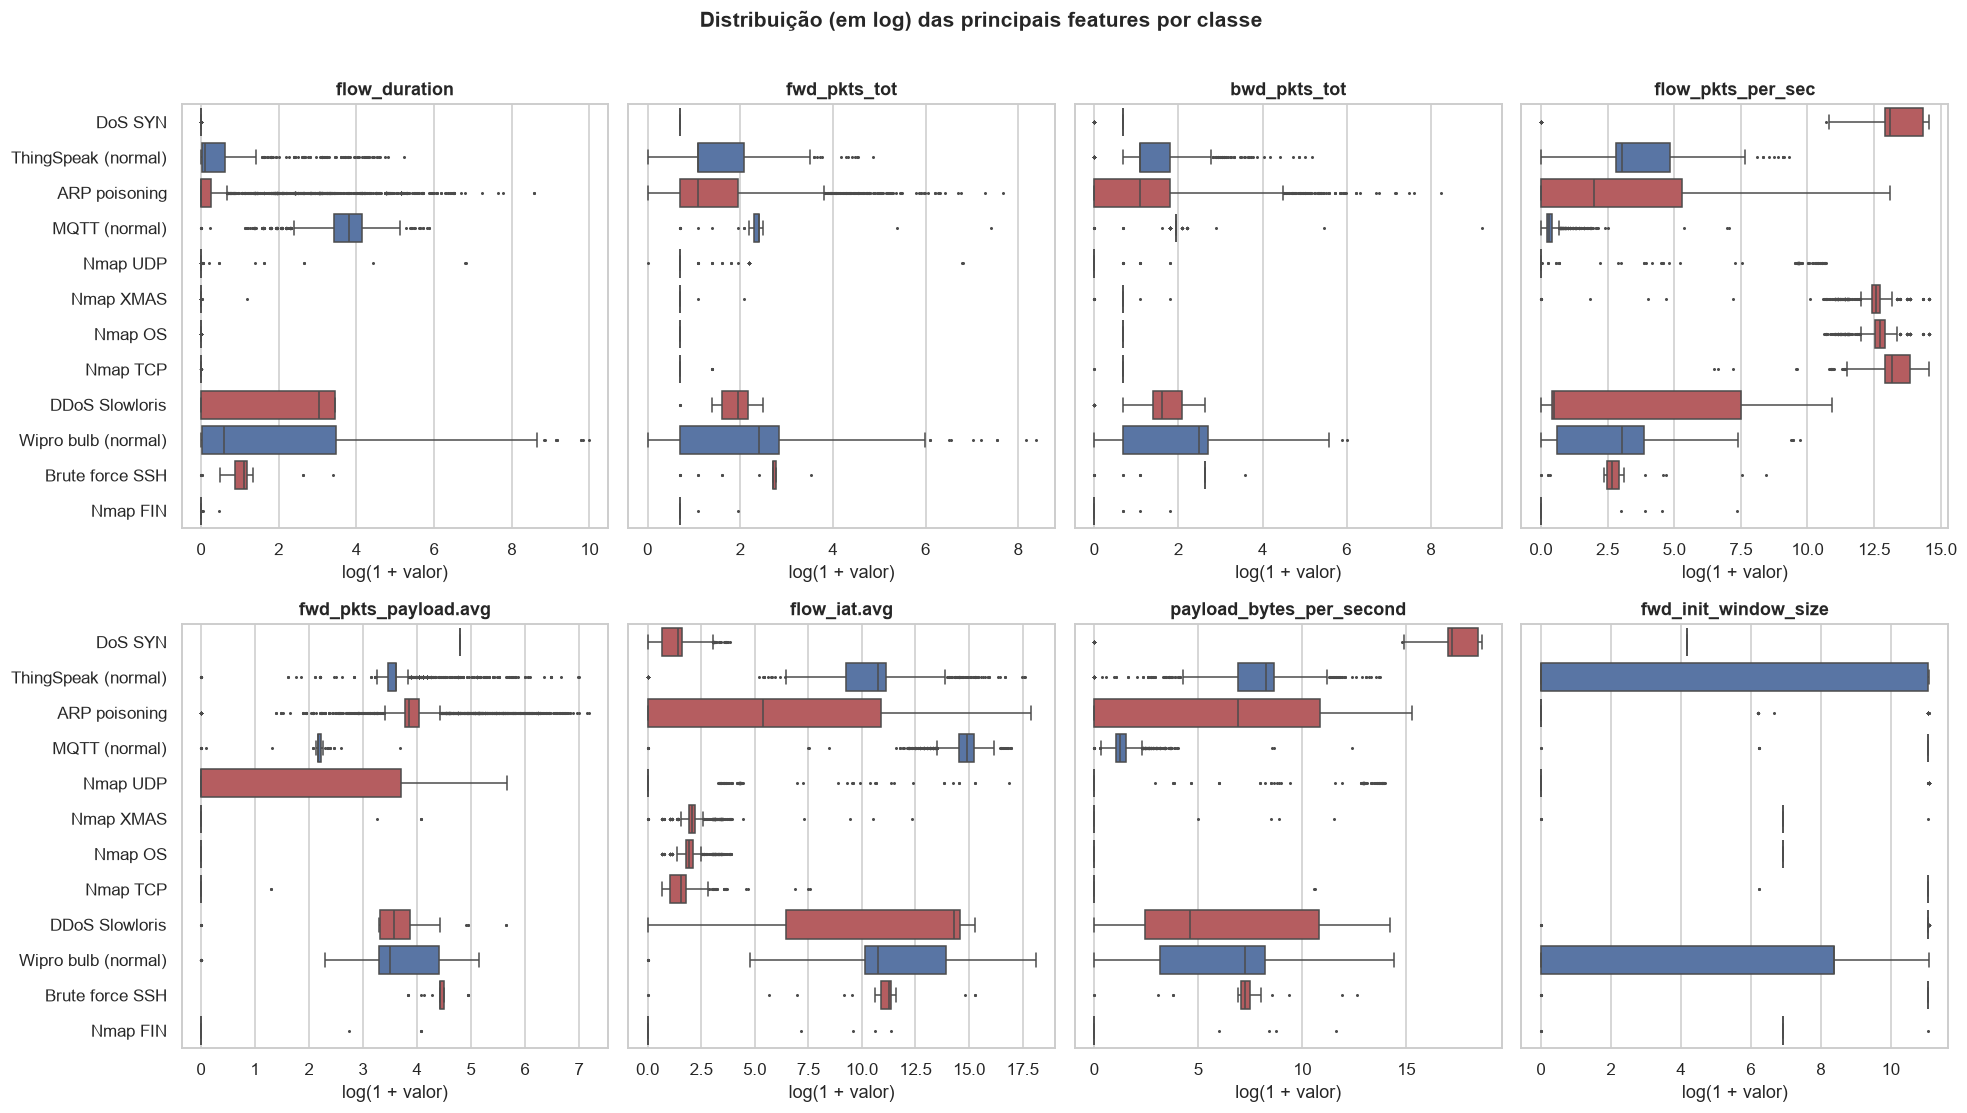

In [8]:
ordem = cont.index.tolist()
fig, axes = plt.subplots(2, 4, figsize=(18, 10), sharey=True)
plot_df = df.assign(Classe=df["Attack_type"].map(NOMES))
for ax, c in zip(axes.flat, CHAVE):
    sns.boxplot(data=plot_df.assign(v=np.log1p(plot_df[c])), y="Classe", x="v", order=[NOMES[o] for o in ordem],
                hue="Grupo", palette=CORES, dodge=False, legend=False, fliersize=1, ax=ax)
    ax.set_title(c); ax.set_xlabel("log(1 + valor)"); ax.set_ylabel("")
plt.suptitle("Distribuição (em log) das principais features por classe", y=1.01, fontsize=14, fontweight="bold")
mostrar()

- Cada ataque tem um padrão próprio. O DoS SYN tem fluxos de 1 ou 2 pacotes, duração quase zero e taxa de pacotes altíssima, já que é uma inundação. O Slowloris tem fluxos longos e lentos, porque segura conexões abertas. As varreduras Nmap são fluxos minúsculos, sem payload.
- O tráfego normal (MQTT, ThingSpeak) tem payload e intervalos regulares entre pacotes, como um sensor mandando leituras de tempos em tempos.
- A janela TCP inicial (`fwd_init_window_size`) separa bem as ferramentas de ataque, que usam valores fixos, dos aparelhos reais.
- ARP poisoning, Slowloris e a lâmpada Wipro são as classes mais espalhadas e se sobrepõem ao tráfego do ThingSpeak. É ali que o modelo deve errar mais.

### 2.5 Protocolo e serviço por classe

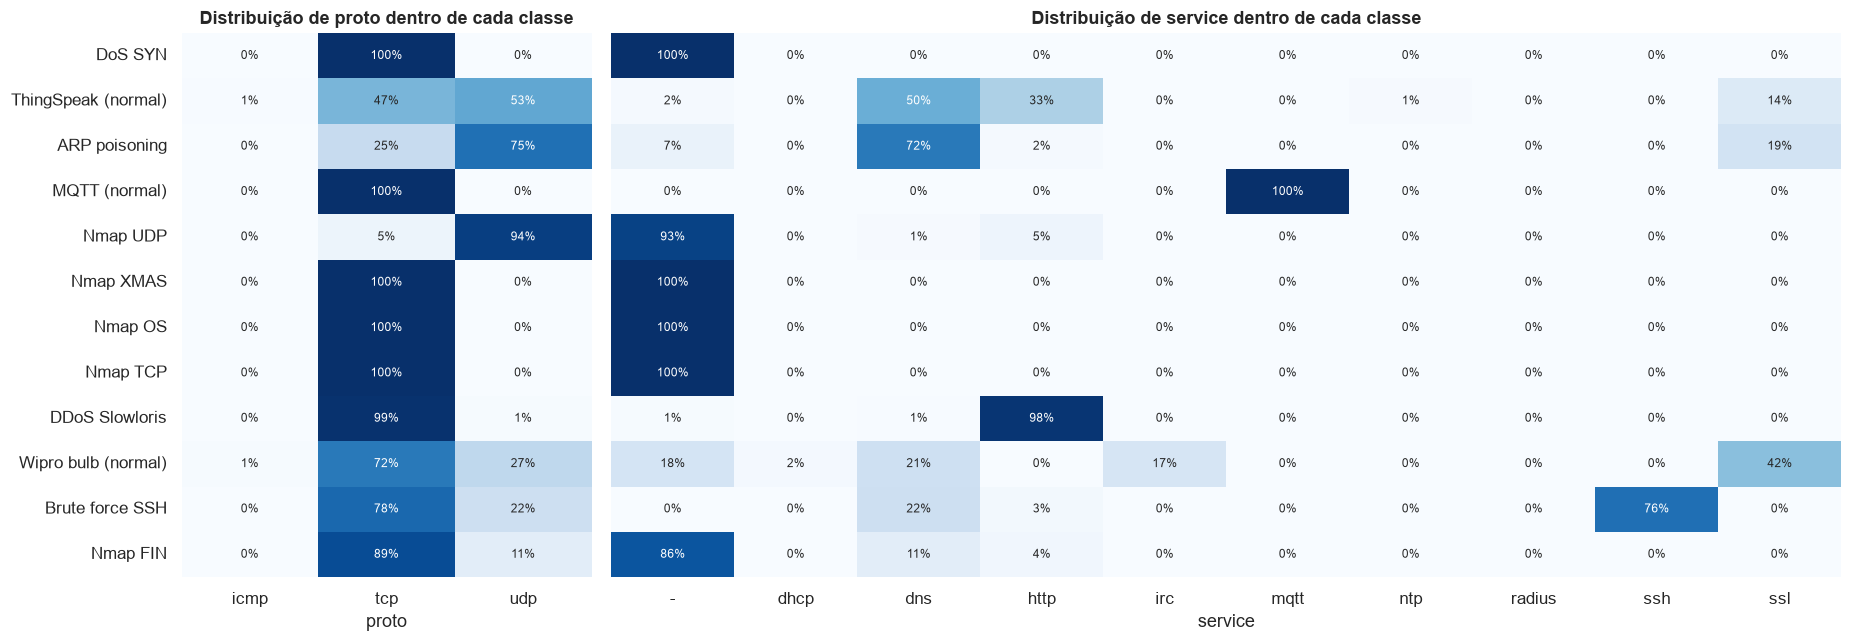

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 3]})
for ax, col in zip(axes, ["proto", "service"]):
    tab = pd.crosstab(df["Attack_type"].map(NOMES), df[col], normalize="index").reindex([NOMES[o] for o in ordem])
    sns.heatmap(tab, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 8})
    ax.set_title(f"Distribuição de {col} dentro de cada classe"); ax.set_xlabel(col); ax.set_ylabel("")
axes[1].set_yticklabels([])
mostrar()

Protocolo e serviço ajudam em algumas classes: o MQTT usa sempre o serviço `mqtt`, o Slowloris usa `http` (98%), o brute force usa `ssh` (76%) e a varredura UDP usa o protocolo `udp` (94%). Mas o DoS e quase todas as varreduras aparecem com serviço `-` (o Zeek não identificou), e o tráfego normal se divide entre `dns`, `http` e `ssl`. Sozinhas, essas duas colunas não resolvem; o modelo precisa das medidas de comportamento.

### 2.6 Outliers

In [10]:
def outliers_iqr(s):
    q1, q3 = float(s.quantile(0.25)), float(s.quantile(0.75)); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

out = pd.DataFrame({"outliers (IQR, escala original)": {c: outliers_iqr(df[c]) for c in CHAVE},
                    "outliers (IQR, após log1p)": {c: outliers_iqr(pd.Series(np.log1p(df[c]))) for c in CHAVE}})
out["% das linhas (original)"] = (out.iloc[:, 0] / len(df) * 100).round(1)
display(out)
print("Classe dos fluxos que são outliers em flow_duration (escala original):")
q1, q3 = float(df["flow_duration"].quantile(0.25)), float(df["flow_duration"].quantile(0.75))
acima = (df["flow_duration"] > q3 + 1.5 * (q3 - q1)).to_numpy()
print(df["Attack_type"][acima].value_counts().head(6).to_string())

,"outliers (IQR, escala original)","outliers (IQR, após log1p)",% das linhas (original)
flow_duration,19171,19171,15.6
fwd_pkts_tot,17662,17662,14.3
bwd_pkts_tot,32364,32364,26.3
flow_pkts_per_sec,0,0,0.0
fwd_pkts_payload.avg,28458,28458,23.1
flow_iat.avg,19180,18448,15.6
payload_bytes_per_second,0,0,0.0
fwd_init_window_size,28458,28458,23.1


Classe dos fluxos que são outliers em flow_duration (escala original):
Attack_type
Thing_Speak            7932
ARP_poisioning         5291
MQTT_Publish           4139
DDOS_Slowloris          531
NMAP_XMAS_TREE_SCAN     371
NMAP_OS_DETECTION       276


Pela regra do IQR, em 6 das 8 variáveis de 14% a 26% das linhas seriam outliers (nas duas taxas, pacotes e bytes por segundo, nenhuma). Só que, com 77% de DoS minúsculo, os quartis ficam colados no DoS, e classes inteiras passam a parecer "atípicas": quase todo o ThingSpeak e o MQTT, o ARP e o Slowloris. Esses pontos são justamente o que diferencia as classes, e não erros de medição, então decidimos mantê-los.

O logaritmo não muda a contagem (ele preserva a ordem dos valores), mas encolhe a escala: um fluxo 1.000 vezes maior fica só umas 7 unidades acima. Isso importa para modelos sensíveis à escala, como a Regressão Logística e o KNN que os colegas do grupo treinam.

### 2.7 Matriz de correlação

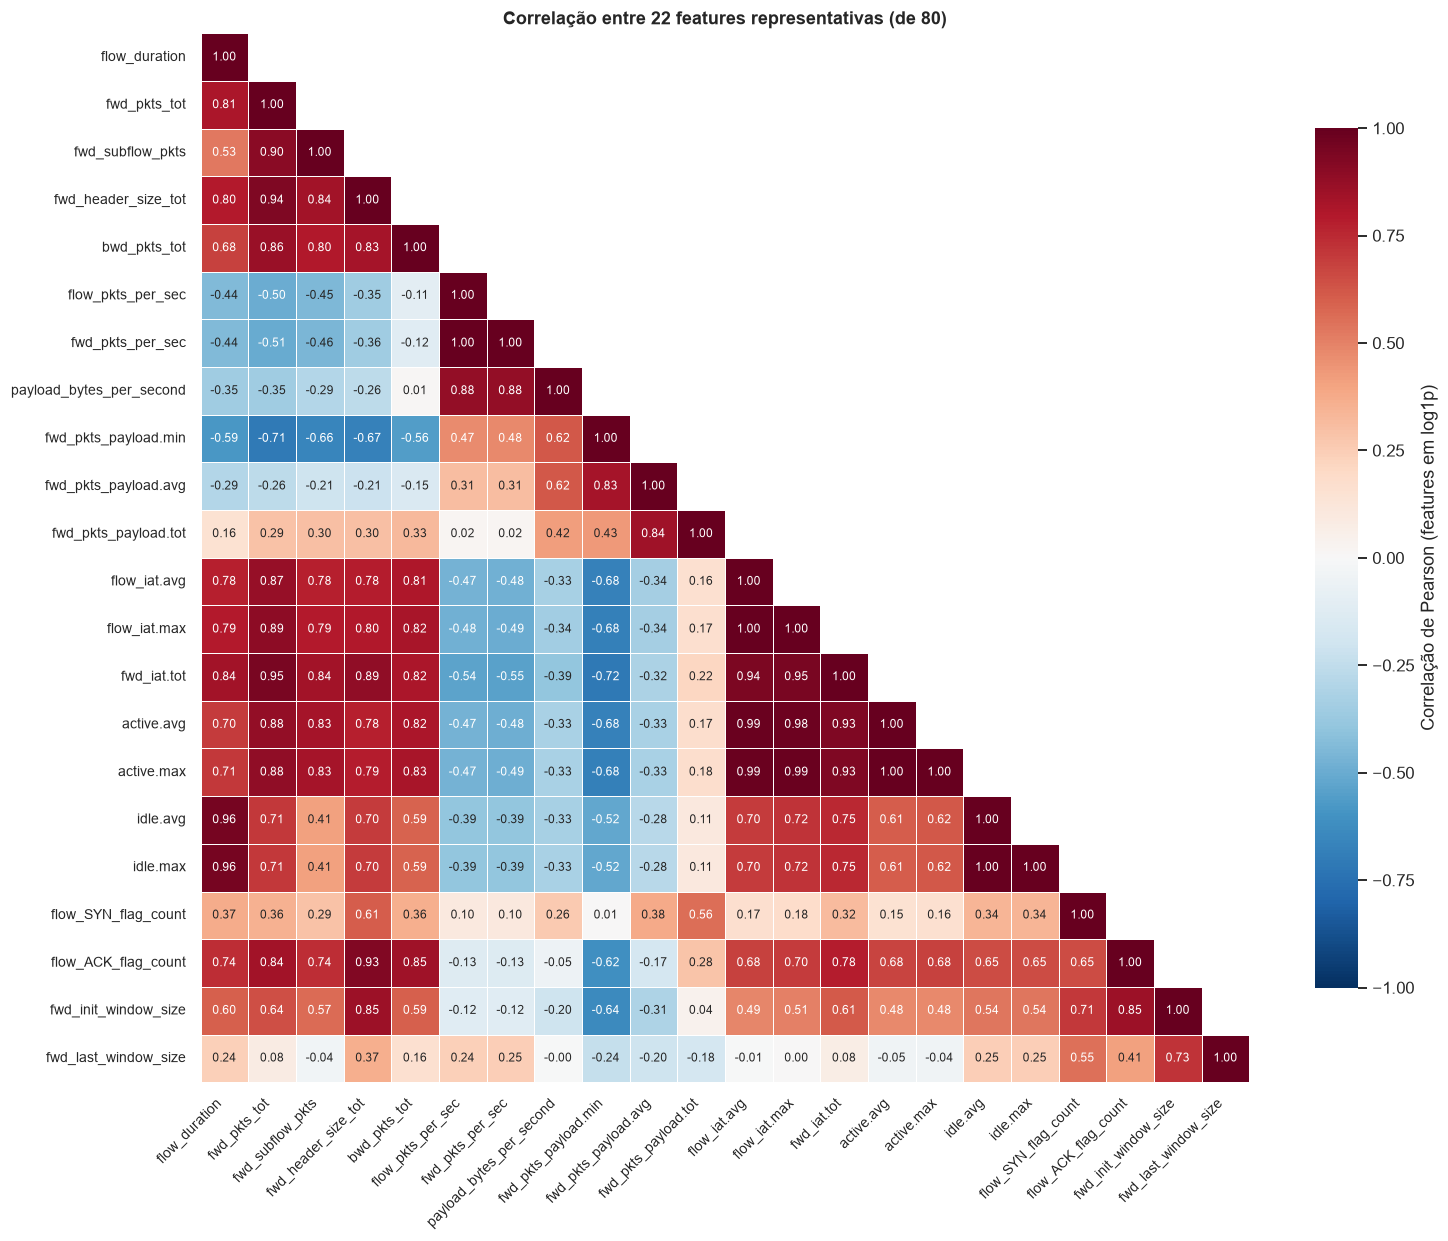

Pares com |r| > 0,95: 105


,feature 1,feature 2,r
2983,idle.max,idle.avg,1.000
2977,idle.min,idle.avg,1.000
2937,active.max,active.tot,1.000
2975,idle.min,idle.max,1.000
376,fwd_pkts_per_sec,flow_pkts_per_sec,1.000
2938,active.max,active.avg,1.000
2982,idle.max,idle.tot,0.999
2475,bwd_iat.max,bwd_iat.tot,0.999
2988,idle.tot,idle.avg,0.999
2948,active.tot,active.avg,0.999


In [11]:
num_feats = num_all.drop(columns=["id.orig_p", "id.resp_p", "bwd_URG_flag_count"])
corr = num_feats.transform(np.log1p).corr()  # todas as 80 features: usada na contagem de pares

# Para o gráfico ficar legível: 22 features representativas de cada grupo (volume, taxas, payload, tempos, flags, janela)
REPRES = ["flow_duration", "fwd_pkts_tot", "fwd_subflow_pkts", "fwd_header_size_tot", "bwd_pkts_tot",
          "flow_pkts_per_sec", "fwd_pkts_per_sec", "payload_bytes_per_second",
          "fwd_pkts_payload.min", "fwd_pkts_payload.avg", "fwd_pkts_payload.tot",
          "flow_iat.avg", "flow_iat.max", "fwd_iat.tot", "active.avg", "active.max", "idle.avg", "idle.max",
          "flow_SYN_flag_count", "flow_ACK_flag_count", "fwd_init_window_size", "fwd_last_window_size"]
corr_rep = corr.loc[REPRES, REPRES]
fig, ax = plt.subplots(figsize=(14, 11.5))
sns.heatmap(corr_rep, mask=np.triu(np.ones(corr_rep.shape, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, annot_kws={"size": 8}, ax=ax,
            cbar_kws={"label": "Correlação de Pearson (features em log1p)", "shrink": 0.8})
ax.grid(False)
ax.set_title("Correlação entre 22 features representativas (de 80)")
plt.xticks(rotation=45, ha="right", fontsize=9); plt.yticks(fontsize=9)
mostrar()

# Pares acima da diagonal (cada par uma vez), sobre as 80 features
vals = corr.to_numpy()
i, j = np.triu_indices_from(vals, k=1)
pares = pd.DataFrame({"feature 1": corr.index[i], "feature 2": corr.columns[j], "r": vals[i, j]})
alto = pares[pares["r"].abs() > 0.95].sort_values("r", ascending=False)
print(f"Pares com |r| > 0,95: {len(alto)}")
alto.head(10).round(3)

- O gráfico mostra 22 das 80 variáveis, uma ou duas de cada grupo, para ficar legível. A contagem de pares usa as 80.
- Há muita redundância. `fwd_pkts_per_sec` × `flow_pkts_per_sec`, `idle.avg` × `idle.max` e `active.avg` × `active.max` têm correlação de 1,00, e `fwd_pkts_tot`, `fwd_subflow_pkts` e `fwd_header_size_tot` ficam entre 0,84 e 0,94. Em geral são o mínimo, o máximo, a média e o total da mesma medida.
- O tamanho mínimo do payload (`fwd_pkts_payload.min`) anda no sentido contrário do volume do fluxo (−0,71 com `fwd_pkts_tot`): fluxos grandes quase sempre têm algum pacote vazio, só de controle. É uma informação diferente das outras, e ela vai ser a variável mais importante do modelo (seção 5).
- Ao todo são 105 pares com correlação acima de 0,95. Colunas repetidas não trazem informação nova, deixam o treino mais lento e dividem a importância de uma medida entre as cópias. Por isso usamos um filtro de correlação como seleção de atributos.

### 2.8 Redução de dimensionalidade: PCA e t-SNE

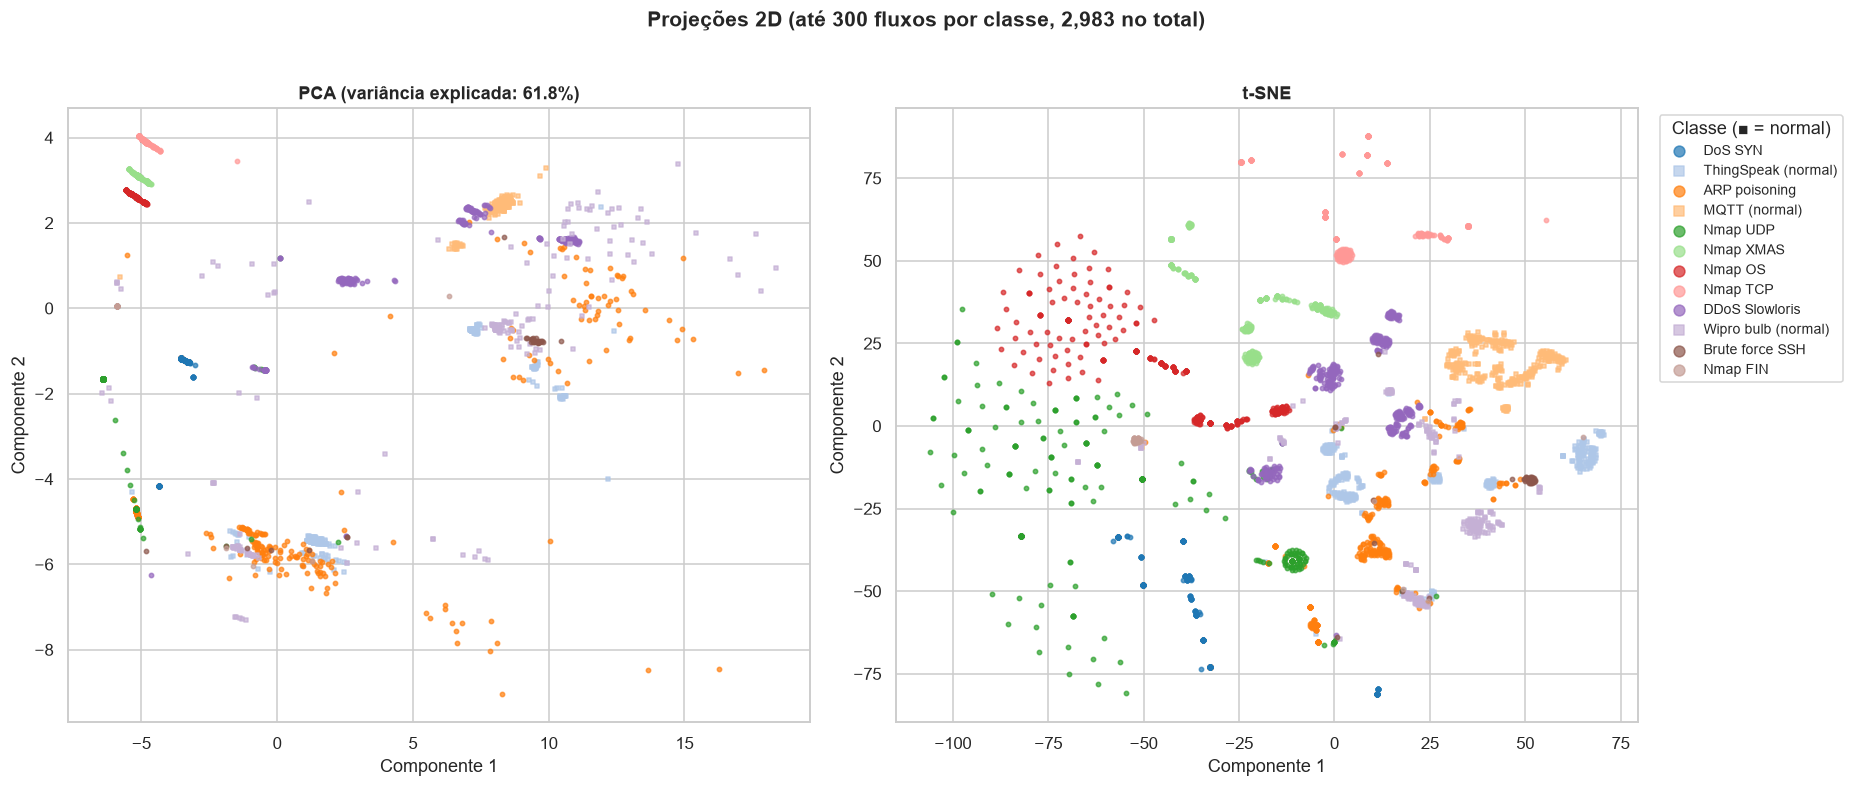

In [12]:
amostra = (df.drop_duplicates(subset=df.columns.drop("id"))
             .sample(frac=1, random_state=RANDOM_STATE)
             .groupby("Attack_type").head(300))
Xv = StandardScaler().fit_transform(np.log1p(amostra[num_feats.columns]))
yv = amostra["Attack_type"].to_numpy()

pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xv)
Xp = pca.transform(Xv)
Xt = TSNE(n_components=2, perplexity=40, random_state=RANDOM_STATE, init="pca").fit_transform(Xv)

paleta = dict(zip(ordem, sns.color_palette("tab20", len(ordem))))
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, X2, tit in [(axes[0], Xp, f"PCA (variância explicada: {pca.explained_variance_ratio_.sum():.1%})"),
                    (axes[1], Xt, "t-SNE")]:
    for cls in ordem:
        m = yv == cls
        ax.scatter(X2[m, 0], X2[m, 1], s=8, alpha=0.7, color=paleta[cls], label=NOMES[cls],
                   marker="o" if cls not in NORMAIS else "s")
    ax.set_title(tit); ax.set_xlabel("Componente 1"); ax.set_ylabel("Componente 2")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", markerscale=2.5, fontsize=9, title="Classe (■ = normal)")
plt.suptitle(f"Projeções 2D (até 300 fluxos por classe, {len(amostra):,} no total)", y=1.02, fontsize=14, fontweight="bold")
mostrar()

As duas primeiras componentes do PCA explicam 61,8% da variância, e várias classes já aparecem como faixas separadas (as varreduras TCP, XMAS e OS, no canto de cima à esquerda). No t-SNE, quase toda classe forma o seu próprio grupo, inclusive as varreduras e o brute force SSH, o que mostra que as medidas de fluxo carregam bastante informação.

As regiões misturadas são as do ARP poisoning com o tráfego normal (ThingSpeak e Wipro) e alguns fluxos do Slowloris, e é ali que o modelo deve errar. Como o PCA (linear) separa pior que o t-SNE, um modelo não linear como o Gradient Boosting tende a ir bem.

## 3. Pré-processamento dos Dados

| Etapa | Técnica | Por quê |
|---|---|---|
| Limpeza | Remove as 5.195 duplicatas exatas (antes do split), o `id`, as portas e a coluna constante | Duplicata exata é o mesmo fluxo registrado duas vezes; o `id` entrega a classe; as portas são coisa do laboratório; a coluna constante não informa nada |
| Valores faltantes | `SimpleImputer` (mediana / moda) no pipeline | Hoje não há nulos, mas um IDS de verdade recebe fluxos incompletos |
| Transformação e escala | `log1p` + `StandardScaler` | Com skew mediano de 27, o log encolhe as caudas. Para o Gradient Boosting essas duas etapas não mudam nada (árvores só olham a ordem dos valores); elas ficam porque o pipeline é comum ao grupo, e os modelos dos colegas (Regressão Logística, KNN) dependem da escala |
| Variáveis categóricas | `OneHotEncoder` em `proto` e `service` | São nominais, sem ordem; `handle_unknown="ignore"` evita erro com serviços novos |
| Seleção de atributos | Filtro de correlação: remove uma coluna de cada par com \|r\| > 0,95, ajustado no treino | Tira 37 das 78 colunas numéricas: treino mais rápido e importâncias mais fáceis de ler |
| Balanceamento | Reduz o DoS SYN para 10.000 (undersampling) + SMOTE opcional nas 3 classes mais raras | O DoS ocupa 77% da base e é muito repetitivo; o SMOTE cria exemplos das classes com menos de 300 linhas |

Sem as portas, muitos fluxos ficam idênticos: os 90 mil fluxos de DoS SYN viram só 57 comportamentos diferentes, porque cada pacote da inundação é igual aos outros e só a porta de origem mudava. Mantivemos essas repetições, porque elas mostram a frequência real do tráfego (num DoS chegam mesmo milhares de fluxos iguais). Para não inflar o resultado, a seção 5 também avalia o modelo só nos fluxos do teste que nunca apareceram no treino.

Undersampling, SMOTE, escala e filtro de correlação ficam dentro do `Pipeline` e são ajustados só no treino de cada fold. A validação e o teste mantêm a distribuição real (77% de DoS), o que evita vazamento de dados.

In [13]:
# 1) Duplicatas exatas da captura (mesmo fluxo registrado duas vezes, inclusive portas) saem antes do split
# 2) Depois saem id, portas e a coluna constante
df_model = (df.drop(columns=["id", "bwd_URG_flag_count", "Grupo"])
              .drop_duplicates()
              .drop(columns=["id.orig_p", "id.resp_p"])
              .reset_index(drop=True))
print("Antes:", df.shape, "| depois:", df_model.shape)
distintos = df_model.drop_duplicates()
print(f"Vetores de features distintos (sem as portas): {len(distintos):,}")
pd.concat([df["Attack_type"].value_counts().rename("original"),
           df_model["Attack_type"].value_counts().rename("sem duplicatas"),
           distintos["Attack_type"].value_counts().rename("comportamentos distintos")], axis=1)

Antes: (123117, 86) | depois: (117922, 81)


Vetores de features distintos (sem as portas): 18,283


,original,sem duplicatas,comportamentos distintos
Attack_type,,,
DOS_SYN_Hping,94659,90089,57
Thing_Speak,8108,7654,7599
ARP_poisioning,7750,7625,5298
MQTT_Publish,4146,4142,4141
NMAP_UDP_SCAN,2590,2584,196
NMAP_XMAS_TREE_SCAN,2010,2010,80
NMAP_OS_DETECTION,2000,2000,75
NMAP_TCP_scan,1002,1002,44
DDOS_Slowloris,534,533,533


In [14]:
class FiltroCorrelacao(BaseEstimator, TransformerMixin):
    """Remove uma coluna de cada par com |correlação| acima do limiar (aprendido só no fit)."""
    def __init__(self, limiar=0.95):
        self.limiar = limiar

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        c = np.nan_to_num(np.abs(np.corrcoef(X, rowvar=False)))
        self.manter_ = ~(np.triu(c, k=1) > self.limiar).any(axis=0)
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.manter_]

TARGET = "Attack_type"
X = df_model.drop(columns=TARGET)
y = df_model[TARGET]
cat_features = ["proto", "service"]
num_features = [c for c in X.columns if c not in cat_features]

preprocessor = ColumnTransformer([
    ("num", SkPipeline([("imp", SimpleImputer(strategy="median")),
                        ("log", FunctionTransformer(np.log1p)),
                        ("scaler", StandardScaler()),
                        ("corr", FiltroCorrelacao(0.95))]), num_features),
    ("cat", SkPipeline([("imp", SimpleImputer(strategy="most_frequent")),
                        ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
])

### Divisão treino/teste
Holdout estratificado 80/20: o teste fica guardado até a avaliação final. Os hiperparâmetros são escolhidos com validação cruzada estratificada de 5 folds no treino. A estratificação é obrigatória aqui: sem ela, uma classe com 28 linhas poderia sumir do teste ou de algum fold.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Treino: {X_train.shape} | Teste: {X_test.shape}")
display(pd.DataFrame({"treino": y_train.value_counts(), "teste": y_test.value_counts()}))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

n_sel = preprocessor.fit(X_train).named_transformers_["num"].named_steps["corr"].manter_.sum()
print(f"Filtro de correlação (ajustado no treino): {len(num_features)} → {n_sel} features numéricas")

Treino: (94337, 80) | Teste: (23585, 80)


,treino,teste
Attack_type,,
DOS_SYN_Hping,72071,18018
Thing_Speak,6123,1531
ARP_poisioning,6100,1525
MQTT_Publish,3314,828
NMAP_UDP_SCAN,2067,517
NMAP_XMAS_TREE_SCAN,1608,402
NMAP_OS_DETECTION,1600,400
NMAP_TCP_scan,802,200
DDOS_Slowloris,426,107


Filtro de correlação (ajustado no treino): 78 → 41 features numéricas


## 4. Treinamento do Modelo: Gradient Boosting

Modelo: `HistGradientBoostingClassifier`, do scikit-learn, um ensemble de árvores por boosting.

**Como funciona.** O modelo treina árvores de decisão em sequência, e cada nova árvore tenta corrigir os erros que as anteriores ainda cometem. A previsão final soma a contribuição de todas elas, e a taxa de aprendizado (`learning_rate`) controla o tamanho de cada correção. Com 12 classes, cada rodada treina 12 árvores, uma por classe. A versão "Hist" agrupa os valores em faixas (histogramas), o que deixa o treino rápido mesmo com 94 mil fluxos.

**Por que ele combina com este problema:**
- capta relações não lineares, e a EDA mostrou que as classes se separam bem de forma não linear (t-SNE), mas pior de forma linear (PCA);
- por ser baseado em árvores, não depende da escala das variáveis e lida bem com distribuições muito assimétricas;
- aceita pesos por classe (`class_weight`), o que ajuda com o desbalanceamento.

**Como treinamos:**
- holdout 80/20 estratificado (seção 3) e validação cruzada estratificada de 5 folds no treino;
- `RandomizedSearchCV` com 30 combinações × 5 folds (150 treinos), buscando o maior F1 macro. Usar ou não o SMOTE também entra na busca;
- a busca completa leva de 10 a 13 minutos. O resultado fica salvo em `modelos/busca_gb.joblib`, e a importância das variáveis, que leva uns 4 minutos, em `modelos/importancia_gb.joblib`. Nas próximas execuções o notebook só carrega esses arquivos. Para treinar de novo, use `RETREINAR = True` na primeira célula.

| Hiperparâmetro | O que controla | Faixa testada |
|---|---|---|
| `learning_rate` | Tamanho da correção de cada rodada | 0,03 a 0,3 (escala log) |
| `max_iter` | Máximo de rodadas de boosting; o modelo para antes se a validação interna parar de melhorar (*early stopping*) | 100 a 400 |
| `max_depth` | Profundidade máxima de cada árvore | sem limite, 6 ou 10 |
| `min_samples_leaf` | Mínimo de fluxos por folha (evita decorar ruído) | 5 a 50 |
| `l2_regularization` | Penalidade que suaviza as previsões das folhas | 0,001 a 1 (escala log) |
| `class_weight` | Peso extra para as classes raras | nenhum ou `balanced` |
| `smote` | Gerar exemplos sintéticos das 3 classes mais raras | sim ou não |

In [16]:
# Dicionários classe -> nº de amostras (Any: os stubs do imblearn só declaram str, mas dict é aceito)
REDUZ_DOS: Any = {"DOS_SYN_Hping": 10000}
RARAS: Any = {"Metasploit_Brute_Force_SSH": 300, "NMAP_FIN_SCAN": 300, "Wipro_bulb": 300}

pipe = Pipeline([("prep", preprocessor),
                 ("under", RandomUnderSampler(sampling_strategy=REDUZ_DOS, random_state=RANDOM_STATE)),
                 ("smote", SMOTE(sampling_strategy=RARAS, k_neighbors=3, random_state=RANDOM_STATE)),
                 ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE))])

espaco = {
    "smote": [SMOTE(sampling_strategy=RARAS, k_neighbors=3, random_state=RANDOM_STATE), "passthrough"],
    "model__learning_rate": loguniform(0.03, 0.3),
    "model__max_iter": randint(100, 400),
    "model__max_depth": [None, 6, 10],
    "model__min_samples_leaf": randint(5, 50),
    "model__l2_regularization": loguniform(1e-3, 1),
    "model__class_weight": [None, "balanced"],
}

In [17]:
def treinar_busca() -> RandomizedSearchCV:
    inicio = time.perf_counter()
    b = RandomizedSearchCV(pipe, espaco, n_iter=30, scoring="f1_macro", cv=cv,
                           n_jobs=-1, random_state=RANDOM_STATE, refit=True)
    b.fit(X_train, y_train)
    os.makedirs(os.path.dirname(ARQ_MODELO), exist_ok=True)
    joblib.dump({"busca": b, "versoes": VERSOES}, ARQ_MODELO)
    print(f"Busca concluída em {(time.perf_counter() - inicio) / 60:.1f} min e salva em {ARQ_MODELO}")
    return b

def carregar_busca() -> RandomizedSearchCV | None:
    # Só reaproveita o arquivo se ele abrir sem erro e tiver sido salvo com as mesmas versões das bibliotecas
    if RETREINAR or not os.path.exists(ARQ_MODELO):
        return None
    try:
        salvo = joblib.load(ARQ_MODELO)
    except Exception as erro:
        print(f"Não foi possível abrir {ARQ_MODELO} ({type(erro).__name__}): o modelo será treinado de novo (~10-13 min)")
        return None
    if not isinstance(salvo, dict) or salvo.get("versoes") != VERSOES:
        versoes = salvo.get("versoes") if isinstance(salvo, dict) else "desconhecidas"
        print(f"{ARQ_MODELO} foi salvo com outras versões ({versoes}; aqui: {VERSOES}): o modelo será treinado de novo (~10-13 min)")
        return None
    print(f"Busca carregada de {ARQ_MODELO} (para refazer o treino, use RETREINAR = True na primeira célula)")
    return salvo["busca"]

carregada = carregar_busca()
modelo_novo = carregada is None
# Tipo declarado: assim as células seguintes sabem que `busca` nunca é None
busca: RandomizedSearchCV = treinar_busca() if carregada is None else carregada
best = cast(Pipeline, busca.best_estimator_)
print(f"F1 macro CV (melhor combinação) = {busca.best_score_:.4f} ± {busca.cv_results_['std_test_score'][busca.best_index_]:.4f}")

Busca carregada de modelos/busca_gb.joblib (para refazer o treino, use RETREINAR = True na primeira célula)
F1 macro CV (melhor combinação) = 0.9575 ± 0.0140


### Melhores hiperparâmetros encontrados

In [18]:
for k, v in busca.best_params_.items():
    if k == "smote":
        v = "passthrough (sem SMOTE)" if v == "passthrough" else "SMOTE"
    elif isinstance(v, float):
        v = round(v, 4)
    print(f"   {k.replace('model__', '')}: {v}")

   class_weight: None
   l2_regularization: 0.2453
   learning_rate: 0.0458
   max_depth: None
   max_iter: 120
   min_samples_leaf: 43
   smote: passthrough (sem SMOTE)


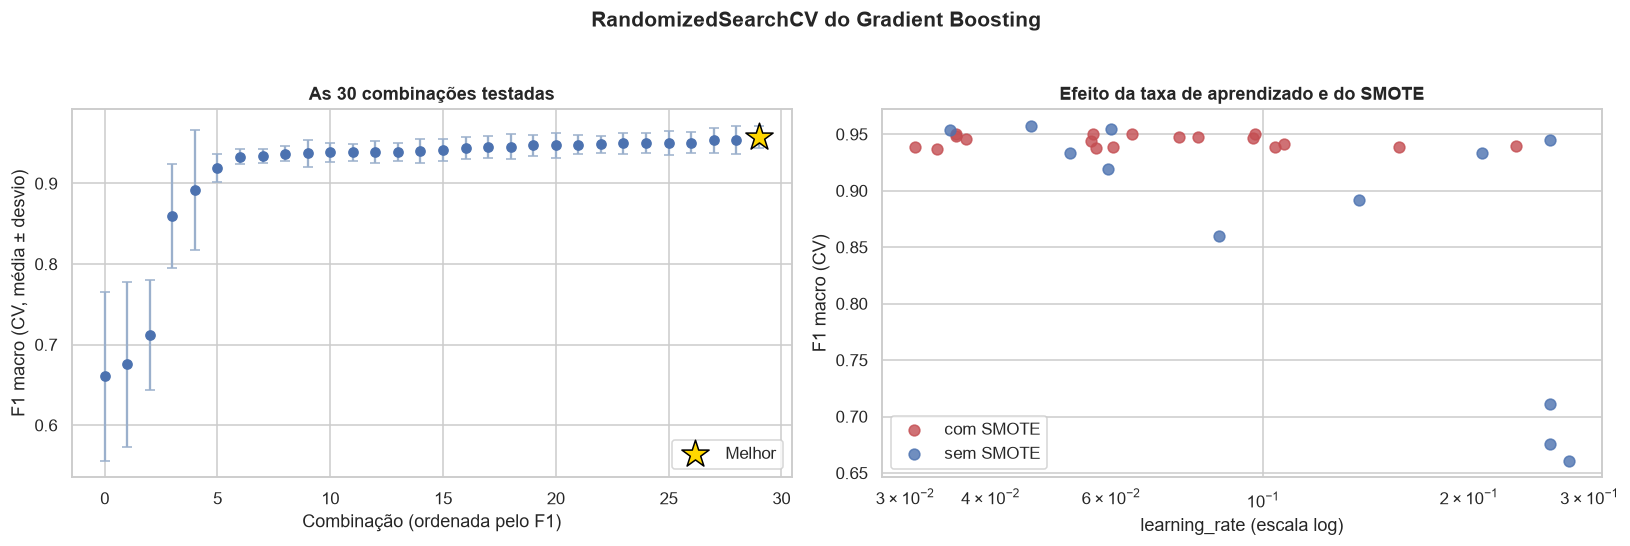

In [19]:
res = pd.DataFrame(busca.cv_results_)
res["usa_smote"] = res["param_smote"].map(lambda v: "sem SMOTE" if v == "passthrough" else "com SMOTE")
ordem_res = res.sort_values("mean_test_score").reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].errorbar(range(len(ordem_res)), ordem_res["mean_test_score"], yerr=ordem_res["std_test_score"],
                 fmt="o", color=CORES["Normal"], ecolor="#9BB0CC", capsize=3)
axes[0].scatter(len(ordem_res) - 1, busca.best_score_, marker="*", s=350, c="gold", edgecolor="black", zorder=5, label="Melhor")
axes[0].set_xlabel("Combinação (ordenada pelo F1)"); axes[0].set_ylabel("F1 macro (CV, média ± desvio)")
axes[0].set_title("As 30 combinações testadas"); axes[0].legend()
for grupo, cor in [("com SMOTE", CORES["Ataque"]), ("sem SMOTE", CORES["Normal"])]:
    sub = res[res["usa_smote"] == grupo]
    axes[1].scatter(sub["param_model__learning_rate"].astype(float), sub["mean_test_score"], color=cor, s=50, alpha=0.8, label=grupo)
axes[1].set_xscale("log"); axes[1].set_xlabel("learning_rate (escala log)"); axes[1].set_ylabel("F1 macro (CV)")
axes[1].set_title("Efeito da taxa de aprendizado e do SMOTE"); axes[1].legend()
plt.suptitle("RandomizedSearchCV do Gradient Boosting", y=1.03, fontsize=14, fontweight="bold")
mostrar()

- 24 das 30 combinações ficaram entre 0,92 e 0,958 de F1 macro, então o modelo é estável: a maioria das configurações razoáveis funciona bem.
- As 5 piores (F1 de 0,66 a 0,89) foram todas sem SMOTE, e as três mais baixas tinham taxa de aprendizado alta (perto de 0,27). Com passos grandes e sem exemplos extras, o modelo "passa por cima" das classes raras, e o F1 macro cai.
- Com SMOTE, todas as 18 combinações ficaram entre 0,937 e 0,951. Ele funciona como uma rede de segurança para as classes raras.
- Mesmo assim, a melhor combinação (0,958) foi sem SMOTE: taxa de aprendizado baixa (0,046), no máximo 120 rodadas, árvores sem limite de profundidade e folhas com pelo menos 43 fluxos. Folhas grandes já protegem as classes raras sem precisar de exemplos sintéticos. Com o *early stopping*, o modelo final parou em 102 rodadas, o que dá 1.224 árvores (12 por rodada).

## 5. Avaliação do Modelo e Conclusão

### 5.1 Métricas no conjunto de teste
Métricas usadas: acurácia; acurácia balanceada (média do recall de cada classe); precisão, recall e F1 macro (média simples entre as classes, para que as raras pesem igual); F1 ponderado (pesado pelo tamanho de cada classe); e ROC-AUC one-vs-rest macro.

In [20]:
CLASSES = np.array(sorted(y.unique()))

def metricas(m, X_, y_):
    pred = m.predict(X_)
    proba = m.predict_proba(X_)
    return {"Acurácia": accuracy_score(y_, pred), "Acur. balanceada": balanced_accuracy_score(y_, pred),
            "Precisão macro": precision_score(y_, pred, average="macro", zero_division=0),
            "Recall macro": recall_score(y_, pred, average="macro", zero_division=0),
            "F1 macro": f1_score(y_, pred, average="macro", zero_division=0),
            "F1 ponderado": f1_score(y_, pred, average="weighted", zero_division=0),
            "ROC-AUC (OvR)": roc_auc_score(y_, proba, multi_class="ovr", average="macro", labels=m.classes_)}

resultado = pd.Series({**metricas(best, X_test, y_test), "F1 macro (CV treino)": float(busca.best_score_)}, name="Teste")
resultado.round(4).to_frame()

,Teste
Acurácia,0.9975
Acur. balanceada,0.9861
Precisão macro,0.9769
Recall macro,0.9861
F1 macro,0.9811
F1 ponderado,0.9975
ROC-AUC (OvR),1.0000
F1 macro (CV treino),0.9575


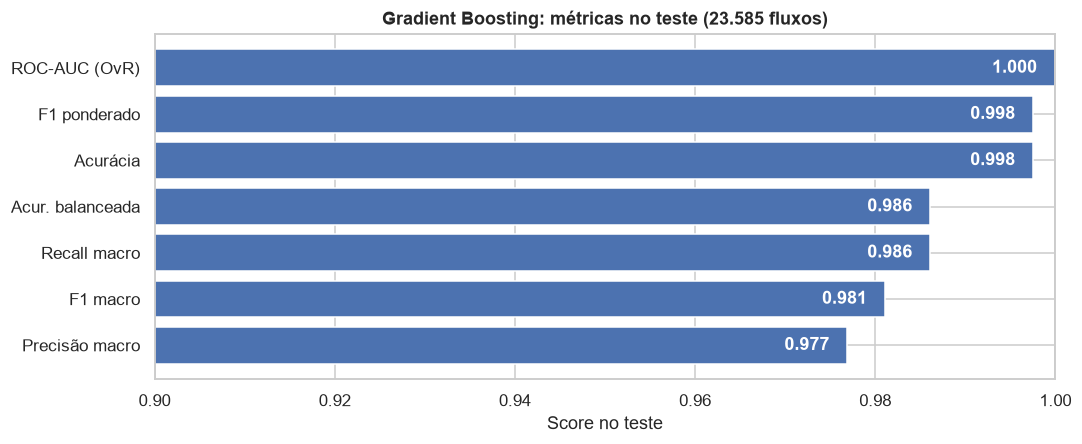

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.2))
plot_m = resultado.drop("F1 macro (CV treino)").sort_values()
valores = plot_m.to_numpy(dtype=float)
ax.barh(plot_m.index, valores, color=CORES["Normal"])
for i, v in enumerate(valores):
    ax.text(float(v) - 0.002, i, f"{v:.3f}", va="center", ha="right", color="white", fontweight="bold")
ax.set_xlim(0.9, 1.0); ax.set_xlabel("Score no teste")
ax.set_title("Gradient Boosting: métricas no teste (23.585 fluxos)")
mostrar()

### 5.2 Desempenho por classe

                            precision    recall  f1-score   support

            ARP_poisioning      0.985     0.992     0.989      1525
            DDOS_Slowloris      0.919     0.953     0.936       107
             DOS_SYN_Hping      1.000     1.000     1.000     18018
              MQTT_Publish      1.000     0.999     0.999       828
Metasploit_Brute_Force_SSH      0.875     1.000     0.933         7
             NMAP_FIN_SCAN      1.000     1.000     1.000         6
         NMAP_OS_DETECTION      1.000     1.000     1.000       400
             NMAP_TCP_scan      0.990     1.000     0.995       200
             NMAP_UDP_SCAN      0.988     0.975     0.981       517
       NMAP_XMAS_TREE_SCAN      1.000     0.998     0.999       402
               Thing_Speak      0.990     0.985     0.987      1531
                Wipro_bulb      0.976     0.932     0.953        44

                  accuracy                          0.998     23585
                 macro avg      0.977     0.98

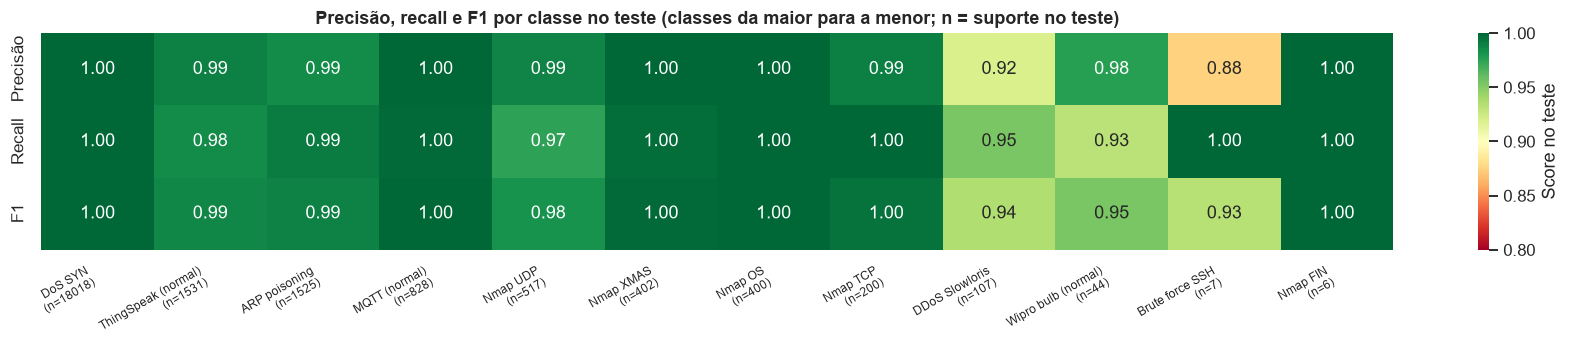

In [22]:
pred_best = best.predict(X_test)
print(classification_report(y_test, pred_best, digits=3, zero_division=0))

por_classe = pd.DataFrame({"Precisão": precision_score(y_test, pred_best, average=None, labels=CLASSES, zero_division=0),
                           "Recall": recall_score(y_test, pred_best, average=None, labels=CLASSES, zero_division=0),
                           "F1": f1_score(y_test, pred_best, average=None, labels=CLASSES, zero_division=0)},
                          index=CLASSES).loc[cont.index.tolist()]
fig, ax = plt.subplots(figsize=(16, 3.4))
sns.heatmap(por_classe.T, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.8, vmax=1, ax=ax, cbar_kws={"label": "Score no teste"})
ax.set_xticklabels([f"{NOMES[c]}\n(n={int((y_test == c).sum())})" for c in por_classe.index], rotation=30, ha="right", fontsize=8)
ax.set_title("Precisão, recall e F1 por classe no teste (classes da maior para a menor; n = suporte no teste)")
mostrar()

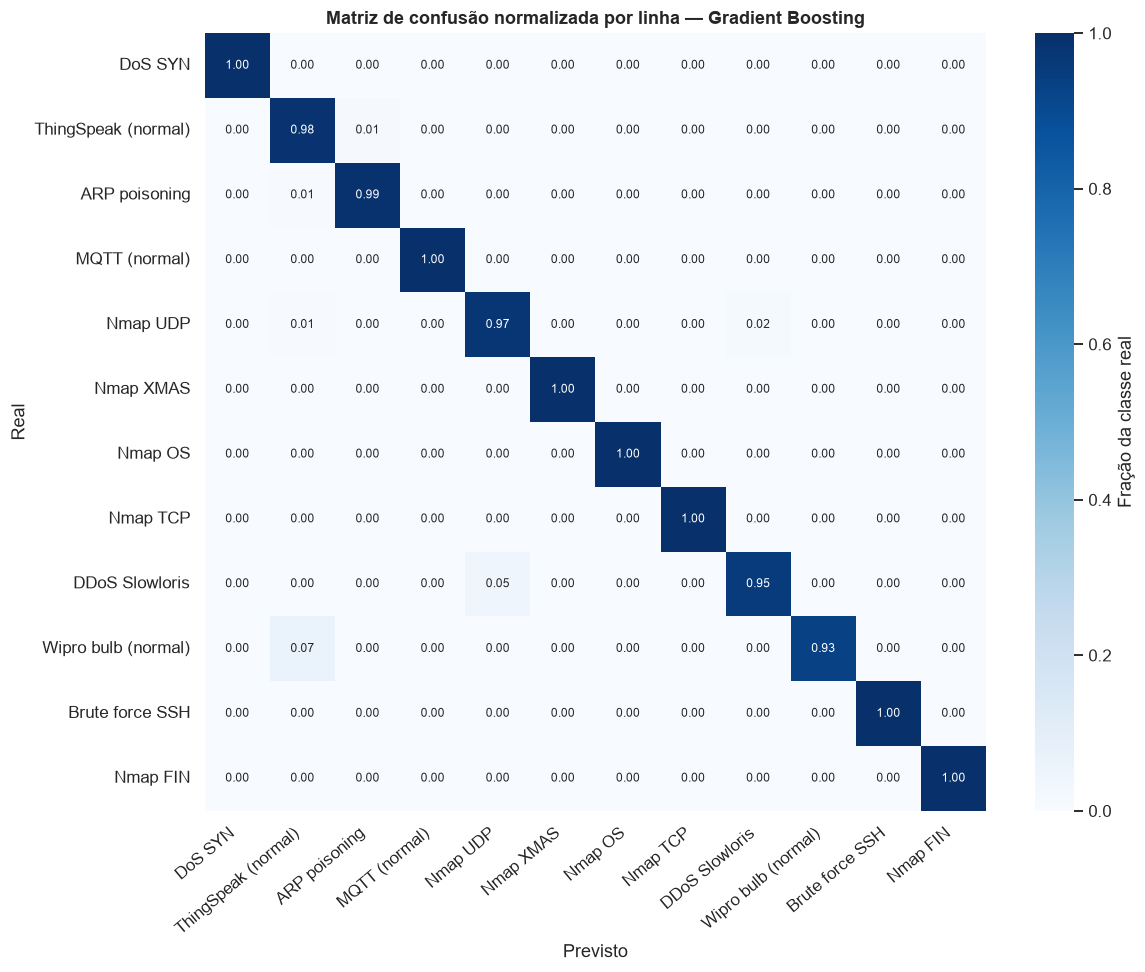

In [23]:
cm = confusion_matrix(y_test, pred_best, labels=cont.index.tolist(), normalize="true")
rot = [NOMES[c] for c in cont.index]
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=rot, yticklabels=rot, ax=ax, vmin=0, vmax=1,
            annot_kws={"size": 8}, cbar_kws={"label": "Fração da classe real"})
ax.set_xlabel("Previsto"); ax.set_ylabel("Real")
ax.set_title("Matriz de confusão normalizada por linha — Gradient Boosting")
plt.xticks(rotation=40, ha="right")
mostrar()

### 5.3 Visão de segurança: ataque × normal

In [24]:
real_ataque = ~y_test.isin(NORMAIS).to_numpy()
prev_ataque = ~pd.Series(pred_best).isin(NORMAIS).to_numpy()
tn, fp, fn, tp = confusion_matrix(real_ataque, prev_ataque, labels=[False, True]).ravel()
print(f"Fluxos de ataque no teste: {tp + fn:,} | detectados como ataque: {tp:,} → taxa de detecção = {tp / (tp + fn):.4%}")
print(f"Fluxos normais no teste:   {tn + fp:,} | marcados como ataque: {fp:,} → taxa de falso alarme = {fp / (tn + fp):.4%}")
print(f"Ataques que passaram como tráfego normal: {fn}")
erro_tipo = ((pred_best != y_test.to_numpy()) & real_ataque & prev_ataque).sum()
print(f"Ataques detectados, mas com o tipo errado: {erro_tipo} ({erro_tipo / (tp + fn):.2%} dos ataques)")

Fluxos de ataque no teste: 21,182 | detectados como ataque: 21,170 → taxa de detecção = 99.9433%
Fluxos normais no teste:   2,403 | marcados como ataque: 22 → taxa de falso alarme = 0.9155%
Ataques que passaram como tráfego normal: 12
Ataques detectados, mas com o tipo errado: 19 (0.09% dos ataques)


### 5.4 Análise de erros: os ataques que passaram despercebidos
A seção anterior diz quantos ataques passaram. Aqui olhamos quais foram e por quê.

In [25]:
perdido = real_ataque & ~prev_ataque
alarme = ~real_ataque & prev_ataque
tipo_errado = real_ataque & prev_ataque & (pred_best != y_test.to_numpy())
nomes_real = y_test.map(NOMES).to_numpy()
nomes_prev = pd.Series(pred_best).map(NOMES).to_numpy()

for titulo, mascara in [("Ataques que passaram como tráfego normal", perdido),
                        ("Tráfego normal marcado como ataque (falso alarme)", alarme),
                        ("Ataques detectados, mas com o tipo errado", tipo_errado)]:
    print(f"{titulo}: {int(mascara.sum())}")
    display(pd.crosstab(pd.Series(nomes_real[mascara], name="real"), pd.Series(nomes_prev[mascara], name="previsto")))

Ataques que passaram como tráfego normal: 12


previsto,ThingSpeak (normal)
real,
ARP poisoning,9
Nmap UDP,3


Tráfego normal marcado como ataque (falso alarme): 22


previsto,ARP poisoning,Nmap UDP
real,,
ThingSpeak (normal),21,1


Ataques detectados, mas com o tipo errado: 19


previsto,ARP poisoning,Brute force SSH,DDoS Slowloris,Nmap TCP,Nmap UDP
real,,,,,
ARP poisoning,0,1,0,2,0
DDoS Slowloris,0,0,0,0,5
Nmap UDP,1,0,9,0,0
Nmap XMAS,1,0,0,0,0


In [26]:
# Os 12 ataques perdidos, um por um, com a confiança do modelo na resposta que deu
confianca = best.predict_proba(X_test[perdido]).max(axis=1)
COLS = ["service", "proto", "flow_duration", "fwd_pkts_tot", "fwd_pkts_payload.min"]
detalhe = X_test.loc[perdido, COLS].assign(real=nomes_real[perdido], previsto=nomes_prev[perdido], confianca=confianca.round(2))
detalhe.sort_values("confianca")

,service,proto,flow_duration,fwd_pkts_tot,fwd_pkts_payload.min,real,previsto,confianca
114248,ntp,udp,0.000000,1,48,Nmap UDP,ThingSpeak (normal),0.48
114252,ntp,udp,0.000000,1,48,Nmap UDP,ThingSpeak (normal),0.48
12738,dns,udp,0.002801,2,36,ARP poisoning,ThingSpeak (normal),0.60
12079,dns,udp,0.000000,1,115,ARP poisoning,ThingSpeak (normal),0.65
14208,dns,udp,0.966817,2,115,ARP poisoning,ThingSpeak (normal),0.68
113576,dhcp,udp,82.709021,5,288,Nmap UDP,ThingSpeak (normal),0.77
16774,dns,udp,0.000238,1,43,ARP poisoning,ThingSpeak (normal),0.77
15296,dns,udp,0.094133,1,47,ARP poisoning,ThingSpeak (normal),0.79
18375,dns,udp,0.034626,1,43,ARP poisoning,ThingSpeak (normal),0.88
15270,dhcp,udp,0.000000,1,300,ARP poisoning,ThingSpeak (normal),0.93


- Os 12 ataques que passaram foram todos classificados como ThingSpeak: 9 de ARP poisoning e 3 de varredura UDP. Todos são fluxos UDP de serviços comuns de rede (DNS, DHCP e NTP).
- Isso tem explicação. No ARP poisoning, o atacante se coloca no meio da conversa e repassa o tráfego das vítimas. Muitos fluxos capturados durante o ataque são, na prática, consultas DNS normais dos próprios aparelhos, e por isso se parecem com o ThingSpeak, que também faz muitas consultas DNS (metade dos seus fluxos).
- Os falsos alarmes são o mesmo problema ao contrário: 21 dos 22 são fluxos do ThingSpeak marcados como ARP.
- Entre os ataques detectados com o tipo errado, o caso mais comum é a varredura UDP confundida com o Slowloris (9 casos) e o contrário (5).
- Em 5 dos 12 ataques perdidos o modelo estava inseguro, com confiança abaixo de 0,7. Um IDS poderia mandar esses casos para revisão manual em vez de liberá-los direto.

### 5.5 Teste mais rigoroso: só fluxos inéditos
Muitos fluxos do teste têm um gêmeo idêntico no treino, principalmente os de DoS. Aqui o modelo é avaliado só nos fluxos do teste cujo vetor de variáveis nunca apareceu no treino. Isso mede se ele generaliza para comportamentos novos, e não só se reconhece cópias.

In [27]:
chaves_treino = set(pd.util.hash_pandas_object(X_train, index=False))
inedito = ~pd.util.hash_pandas_object(X_test, index=False).isin(chaves_treino).to_numpy()
print(f"Fluxos inéditos no teste: {inedito.sum():,} de {len(X_test):,} ({inedito.mean():.1%})")
y_ined = y_test[inedito]
rig = pd.DataFrame({"Teste completo": metricas(best, X_test, y_test),
                    "Só fluxos inéditos": metricas(best, X_test[inedito], y_ined)})
display(rig.loc[["Acurácia", "Acur. balanceada", "F1 macro", "F1 ponderado"]].round(4))
pred_ined = best.predict(X_test[inedito])
f1_ined = pd.Series(f1_score(y_ined, pred_ined, average=None, labels=CLASSES, zero_division=0), index=CLASSES)
print(pd.DataFrame({"fluxos inéditos": y_ined.value_counts(), "F1": f1_ined.round(3)}).dropna().sort_values("fluxos inéditos", ascending=False).to_string())

Fluxos inéditos no teste: 3,614 de 23,585 (15.3%)


,Teste completo,Só fluxos inéditos
Acurácia,0.9975,0.9856
Acur. balanceada,0.9861,0.9330
F1 macro,0.9811,0.9317
F1 ponderado,0.9975,0.9855


                            fluxos inéditos     F1
Thing_Speak                          1521.0  0.989
ARP_poisioning                       1055.0  0.985
MQTT_Publish                          827.0  0.999
DDOS_Slowloris                        107.0  0.936
Wipro_bulb                             44.0  0.953
NMAP_UDP_SCAN                          38.0  0.778
Metasploit_Brute_Force_SSH              7.0  0.933
NMAP_TCP_scan                           7.0  0.875
NMAP_OS_DETECTION                       3.0  1.000
NMAP_XMAS_TREE_SCAN                     3.0  0.800
DOS_SYN_Hping                           2.0  1.000


### 5.6 Interpretação: importância das variáveis (permutation importance no teste)

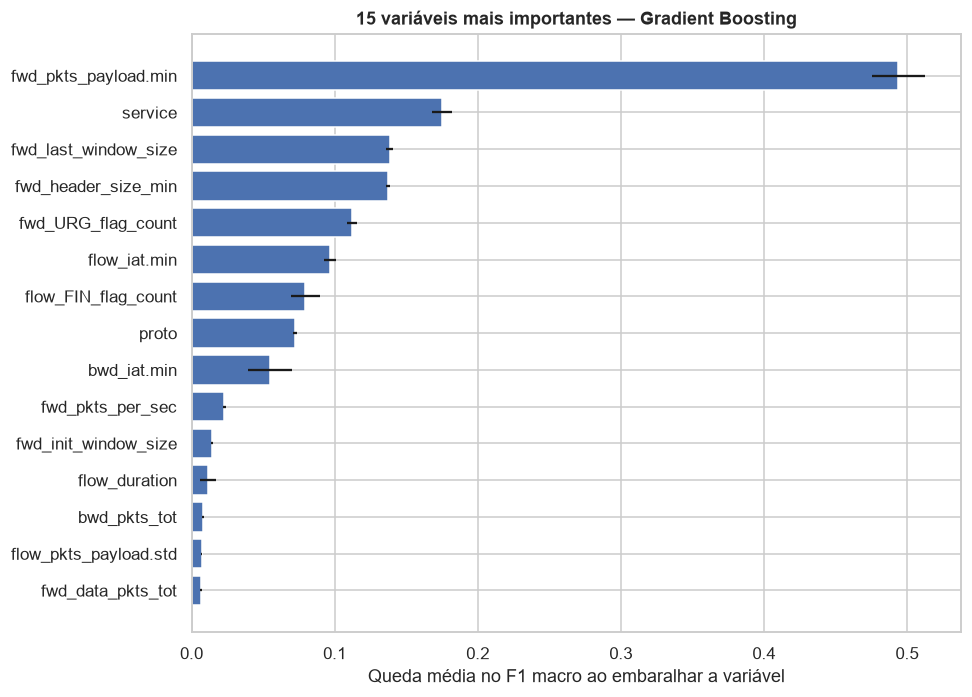

In [28]:
# 80 features × 5 repetições = 400 rodadas de previsão (~4 min): o resultado também fica salvo
# Se o modelo acabou de ser treinado, a importância salva (do modelo anterior) não vale mais
ARQ_IMP = "modelos/importancia_gb.joblib"
pi = None
if not (RETREINAR or modelo_novo) and os.path.exists(ARQ_IMP):
    try:
        pi = joblib.load(ARQ_IMP)
    except Exception as erro:
        print(f"Não foi possível abrir {ARQ_IMP} ({type(erro).__name__}): a importância será recalculada (~4 min)")
if pi is None:
    r = permutation_importance(best, X_test, y_test, scoring="f1_macro", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    pi = {"importances_mean": r["importances_mean"], "importances_std": r["importances_std"]}
    joblib.dump(pi, ARQ_IMP)
imp = pd.Series(pi["importances_mean"], index=X_test.columns).sort_values(ascending=False).head(15).iloc[::-1]
err = pd.Series(pi["importances_std"], index=X_test.columns)[imp.index]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(imp.index, imp.to_numpy(), xerr=err.to_numpy(), color=CORES["Normal"])
ax.set_xlabel("Queda média no F1 macro ao embaralhar a variável")
ax.set_title("15 variáveis mais importantes — Gradient Boosting")
mostrar()

### 5.7 O modelo cabe num dispositivo IoT?
A motivação falava em aparelhos com poucos recursos. Aqui medimos o tamanho do modelo e o tempo para classificar fluxos.

In [29]:
import pickle
modelo_gb = cast(HistGradientBoostingClassifier, best.named_steps["model"])
print(f"Tamanho do pipeline completo: {len(pickle.dumps(best)) / 1e6:.1f} MB")
print(f"Rodadas de boosting: {modelo_gb.n_iter_} × {len(modelo_gb.classes_)} classes = {modelo_gb.n_iter_ * len(modelo_gb.classes_):,} árvores")

t0 = time.perf_counter()
best.predict(X_test)
lote = time.perf_counter() - t0
print(f"Lote de {len(X_test):,} fluxos: {lote:.2f} s, ou {len(X_test) / lote:,.0f} fluxos por segundo")

um_por_vez = X_test.sample(200, random_state=RANDOM_STATE)
tempos = []
for k in range(len(um_por_vez)):
    t0 = time.perf_counter()
    best.predict(um_por_vez.iloc[[k]])
    tempos.append(time.perf_counter() - t0)
print(f"Um fluxo por vez: mediana de {np.median(tempos) * 1000:.0f} ms por fluxo")

Tamanho do pipeline completo: 2.3 MB
Rodadas de boosting: 102 × 12 classes = 1,224 árvores


Lote de 23,585 fluxos: 1.05 s, ou 22,445 fluxos por segundo


Um fluxo por vez: mediana de 45 ms por fluxo


- O pipeline inteiro, com o pré-processamento e as 1.224 árvores, ocupa cerca de 2,3 MB, mais ou menos o tamanho de uma foto de celular.
- Em lote, ele classifica mais de 20 mil fluxos por segundo neste computador. Um fluxo sozinho leva umas dezenas de milissegundos, mas quase todo esse tempo é o custo fixo do pandas e do pipeline, e não das árvores. Por isso vale classificar em pequenos lotes.
- Na prática, o modelo é leve o bastante para rodar no gateway da rede (o roteador ou mini-computador que liga os aparelhos à internet). Dentro de uma lâmpada ou de um sensor, não: eles não têm memória nem processador para isso. E os tempos foram medidos num computador comum, não num gateway de verdade.

### 5.8 Melhorias futuras
- **Mais exemplos das classes raras.** Com 6 ou 7 fluxos de brute force SSH e de varredura FIN no teste, um único erro já derruba o F1 dessas classes de 1,00 para algo entre 0,91 e 0,93. Capturar mais ataques desses tipos é o ganho mais importante.
- **Testar em outra rede.** Os dados vêm de um único laboratório. Outra rede, com outros aparelhos e ferramentas, mostraria se o modelo generaliza.
- **Atacar a confusão ARP × ThingSpeak.** O ARP poisoning acontece na camada 2 (endereços MAC), e a base não tem essa informação, só estatísticas dos fluxos. Juntar dados de ARP/MAC ajudaria. Casos de baixa confiança poderiam ir para revisão manual.
- **Medir num gateway de verdade.** Os tempos da seção 5.7 são de um computador comum. O próximo passo é medir num Raspberry Pi ou roteador e testar versões menores do modelo (menos rodadas, árvores mais rasas).
- **Ajuste por custo.** Deixar passar um ataque custa mais que um alarme falso. Pesos ou limiares por classe podem levar isso em conta.
- **Ataques novos.** Um classificador supervisionado só reconhece o que viu no treino. Combinar com detecção de anomalias (como o *autoencoder* do artigo original) cobriria ataques desconhecidos.

In [30]:
print("MODELO FINAL: Gradient Boosting")
for k, v in resultado.items():
    print(f"  {k:22s}: {v:.4f}")

MODELO FINAL: Gradient Boosting
  Acurácia              : 0.9975
  Acur. balanceada      : 0.9861
  Precisão macro        : 0.9769
  Recall macro          : 0.9861
  F1 macro              : 0.9811
  F1 ponderado          : 0.9975
  ROC-AUC (OvR)         : 1.0000
  F1 macro (CV treino)  : 0.9575


### 5.9 Conclusão

| Métrica | Valor |
|---|---|
| F1 macro (validação cruzada, treino) | 0,958 ± 0,014 |
| **F1 macro (teste)** | **0,981** |
| Acurácia / acurácia balanceada (teste) | 0,998 / 0,986 |
| Precisão / recall macro (teste) | 0,977 / 0,986 |
| ROC-AUC OvR (teste) | 1,000 |
| F1 macro só nos fluxos inéditos | 0,932 |
| Ataques detectados | 99,94% |
| Falso alarme | 0,92% |
| Tamanho do modelo | ~2,3 MB |
| Velocidade em lote | mais de 20 mil fluxos por segundo |

- **Desempenho.** O Gradient Boosting reconheceu os 12 tipos de tráfego com F1 macro de 0,981 no teste. Seis classes passaram de 0,99 (DoS, MQTT e as varreduras XMAS, OS, TCP e FIN), e o ARP e o ThingSpeak ficaram logo abaixo (0,989 e 0,987).
- **Validação × teste.** O F1 da validação cruzada (0,958) é menor que o do teste (0,981) porque cada fold de validação tem só 4 a 6 fluxos das classes mais raras, e um erro nelas derruba a nota do fold (o desvio de ± 0,014 mostra isso). Não é sinal de vazamento, porque o teste não foi usado em nenhuma decisão.
- **Segurança.** 99,94% dos ataques foram detectados (só 12 de 21.182 passaram como normais), com 0,9% de falso alarme (22 de 2.403 fluxos normais).
- **Onde erra.** Quase todos os erros entre ataque e normal são a mesma confusão, ARP poisoning × ThingSpeak, e têm explicação: durante o ARP poisoning, o atacante repassa o tráfego DNS normal das vítimas. Fora isso, o Slowloris e a varredura UDP se confundem entre si, e a lâmpada Wipro às vezes é tomada pelo ThingSpeak (os dois são tráfego normal).
- **Teste mais rigoroso.** Nos fluxos do teste que nunca apareceram no treino (15% do teste), o F1 macro cai para 0,93. Esse é o número mais honesto, já que o 0,98 é inflado pelos DoS repetidos. A maior queda é na varredura UDP inédita (0,78 em 38 fluxos).
- **O que o modelo usa.** O tamanho mínimo do payload enviado domina, seguido do serviço, da janela TCP final, do tamanho mínimo do cabeçalho, das flags URG e FIN e do menor intervalo entre pacotes. O modelo aprendeu o jeito de cada ferramenta montar os pacotes, e não as portas.
- **Custo.** O modelo final tem 2,3 MB e classifica mais de 20 mil fluxos por segundo, então cabe num gateway de rede IoT.
- **Atende às expectativas?** Para este ambiente, sim: detecta quase todos os ataques com poucos alarmes falsos e acerta o tipo com F1 macro de 0,93 mesmo em fluxos novos. As limitações são claras: os ataques foram encenados num único laboratório (o caso das portas mostra isso), as classes raras têm só 6 ou 7 exemplos no teste, e um modelo supervisionado não reconhece ataques que nunca viu. Antes de usar de verdade, seria preciso testar em outra rede.
- **O que aprendemos.** Os números quase perfeitos escondiam três armadilhas: o `id` que recomeça em cada classe, as portas fixas do laboratório e os 90 mil DoS que eram só 57 padrões. Encontrar e tratar essas três foi o que deixou o resultado confiável.